# Phase 2 · Notebook 3: Evaluation and comparison
Reads the test forecasts from Notebook 2 and computes RMSE, MAE and MAPE over the hold-out window (Jan 2018 to Dec 2019).
All metrics are on the original case-count scale, so they can be read directly in cases.

**Inputs:** `outputs/test_forecasts.csv`, `outputs/sarima_intervals.csv`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
FIG_DIR = OUT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.figsize"] = (11, 4)

In [2]:
forecasts = pd.read_csv(OUT / "test_forecasts.csv", parse_dates=["date"], index_col="date")
actual = forecasts["actual"]
model_cols = [c for c in forecasts.columns if c != "actual"]

print("Models:", model_cols)
print(f"Test window: {forecasts.index[0]:%b %Y} to {forecasts.index[-1]:%b %Y} ({len(forecasts)} months)")

Models: ['naive', 'seasonal_naive', 'arima', 'sarima', 'hw_add_log', 'hw_damped_log', 'hw_mul_raw']
Test window: Jan 2018 to Dec 2019 (24 months)


## 1. Error metrics
- **RMSE:** root mean squared error. Penalises large misses most heavily. Same units as cases.
- **MAE:** mean absolute error. The average miss, in cases.
- **MAPE:** mean absolute percentage error. Scale-free, but it weights low-count months heavily. This matters here, because the test window ranges from about 300 to about 10,000 cases a month.

In [3]:
def rmse(a, f):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))

def mae(a, f):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(f))))

def mape(a, f):
    a = np.asarray(a, dtype=float)
    assert (a > 0).all(), "MAPE is undefined when an actual value is zero"
    return float(np.mean(np.abs((a - np.asarray(f)) / a)) * 100)

In [4]:
rows = [{"model": m,
         "RMSE": rmse(actual, forecasts[m]),
         "MAE": mae(actual, forecasts[m]),
         "MAPE (%)": mape(actual, forecasts[m])}
        for m in model_cols]
metrics = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)

base_rmse = metrics.loc[metrics["model"] == "seasonal_naive", "RMSE"].item()
metrics["RMSE gain vs seasonal naive (%)"] = (1 - metrics["RMSE"] / base_rmse) * 100
metrics.round(2)

,model,RMSE,MAE,MAPE (%),RMSE gain vs seasonal naive (%)
0,sarima,2086.59,932.83,35.11,13.58
1,hw_add_log,2142.34,962.96,38.15,11.27
2,seasonal_naive,2414.54,1136.04,32.46,0.00
3,arima,2500.30,1196.42,34.06,-3.55
4,hw_damped_log,2626.17,1426.06,66.20,-8.76
5,hw_mul_raw,2659.98,1438.13,58.66,-10.17
6,naive,2665.49,1432.12,57.77,-10.39


In [5]:
metrics.round(3).to_csv(OUT / "metrics.csv", index=False)

winners = {c: metrics.sort_values(c).iloc[0]["model"] for c in ["RMSE", "MAE", "MAPE (%)"]}
print("Best model by metric:", winners)

Best model by metric: {'RMSE': 'sarima', 'MAE': 'sarima', 'MAPE (%)': 'seasonal_naive'}


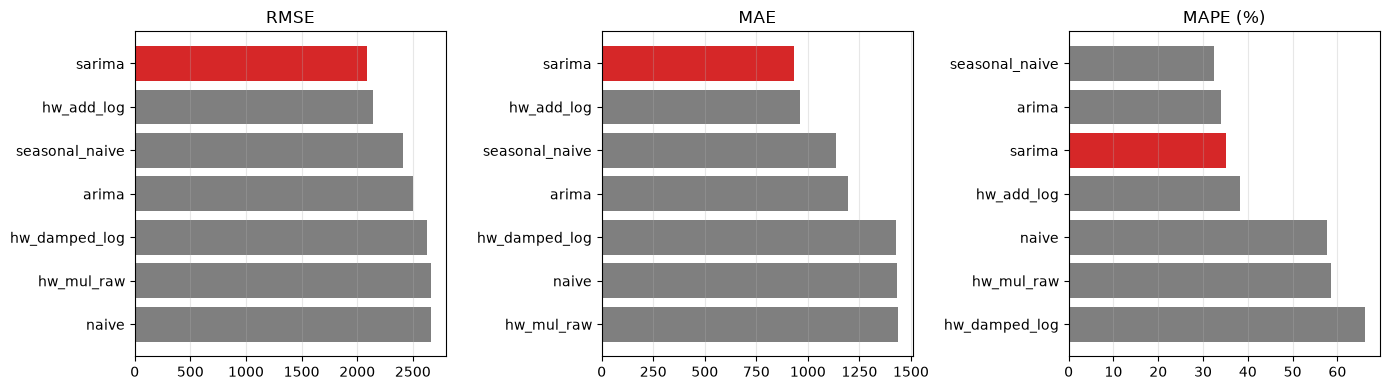

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["RMSE", "MAE", "MAPE (%)"]):
    s = metrics.sort_values(col)
    ax.barh(s["model"], s[col], color=["tab:red" if m == "sarima" else "tab:grey" for m in s["model"]])
    ax.set_title(col)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_metric_comparison.png", dpi=150)
plt.show()

## 2. Error by test year
2018 is a low-incidence year. 2019 includes a large spring outbreak. Splitting by year shows whether each model's error is stable across the two years.

In [7]:
by_year = []
for yr, grp in forecasts.groupby(forecasts.index.year):
    for m in model_cols:
        by_year.append({"year": yr, "model": m,
                        "RMSE": rmse(grp["actual"], grp[m]),
                        "MAE": mae(grp["actual"], grp[m]),
                        "MAPE (%)": mape(grp["actual"], grp[m])})
by_year = pd.DataFrame(by_year)

print("RMSE by year")
print(by_year.pivot(index="model", columns="year", values="RMSE").round(0).sort_values(2019).to_string())
print("\nMAPE (%) by year")
print(by_year.pivot(index="model", columns="year", values="MAPE (%)").round(1).sort_values(2019).to_string())

RMSE by year
year              2018    2019
model                         
sarima           256.0  2940.0
hw_add_log       257.0  3019.0
seasonal_naive   637.0  3355.0
arima            701.0  3466.0
naive           1034.0  3625.0
hw_damped_log    719.0  3644.0
hw_mul_raw       917.0  3648.0

MAPE (%) by year
year            2018  2019
model                     
seasonal_naive  24.6  40.4
arima           26.5  41.6
sarima          21.0  49.2
hw_add_log      25.8  50.5
naive           57.7  57.8
hw_mul_raw      56.0  61.4
hw_damped_log   56.2  76.1


## 3. Actual vs forecast
Top: all models over the test window. Bottom: SARIMA against the actual series, zoomed to the case range. The SARIMA 95% band is left out because it grows to roughly 160,000 cases by the May 2019 peak. That width reflects the model's accumulated uncertainty over 24 steps, not a usable range. The bounds are saved in `outputs/sarima_intervals.csv` for reference.

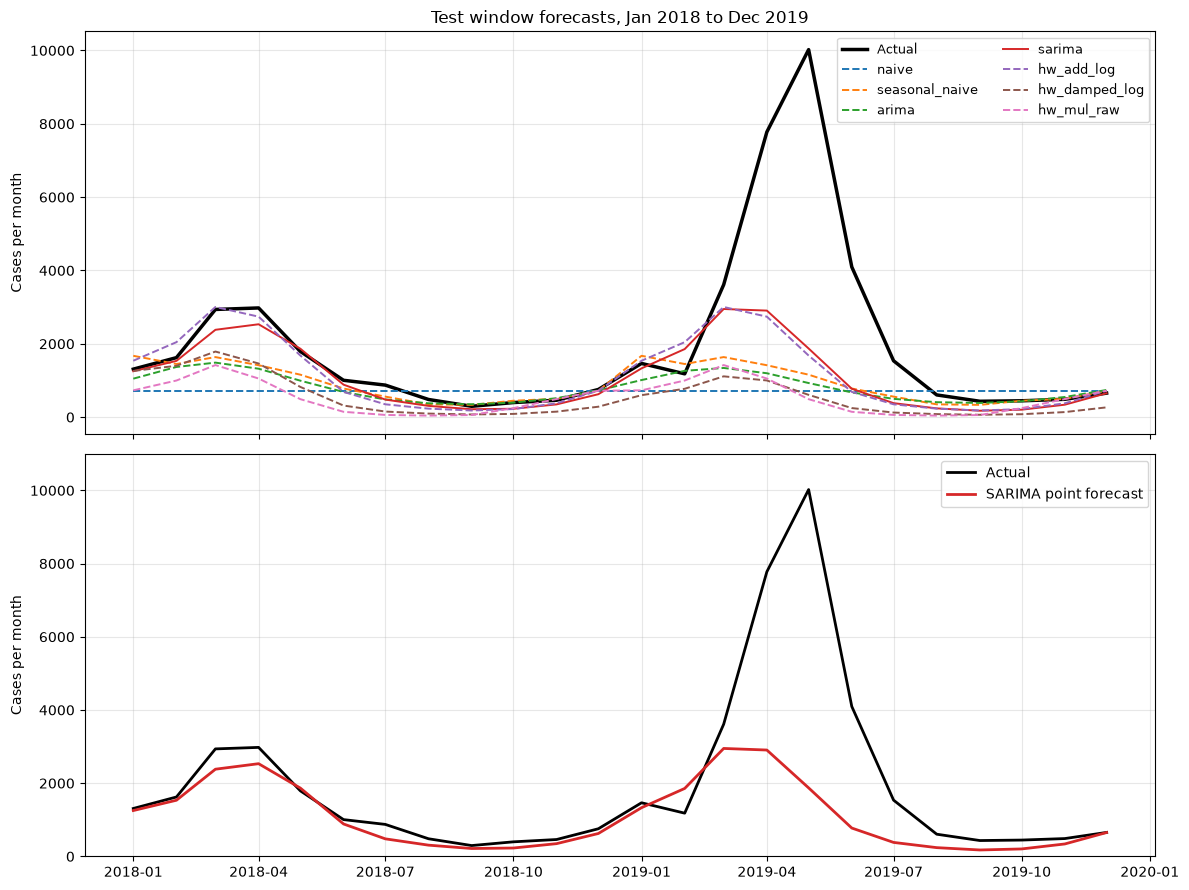

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

ax = axes[0]
ax.plot(actual.index, actual, color="black", lw=2.5, label="Actual")
for m in model_cols:
    ax.plot(forecasts.index, forecasts[m], lw=1.4,
            ls="-" if m == "sarima" else "--", label=m)
ax.set_title("Test window forecasts, Jan 2018 to Dec 2019")
ax.set_ylabel("Cases per month")
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(actual.index, actual, color="black", lw=2, label="Actual")
ax.plot(forecasts.index, forecasts["sarima"], color="tab:red", lw=2, label="SARIMA point forecast")
ax.set_ylim(0, 11000)
ax.set_ylabel("Cases per month")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "08_forecast_comparison.png", dpi=150)
plt.show()

## 4. Month-by-month errors for the best model
The best model is the lowest RMSE. The table shows where it is accurate and where it misses.

In [9]:
best = metrics.loc[0, "model"]
detail = pd.DataFrame({"actual": actual, "forecast": forecasts[best].round(0)})
detail["abs error"] = (detail["actual"] - detail["forecast"]).abs().round(0)
detail["APE (%)"] = (detail["abs error"] / detail["actual"] * 100).round(1)
print("Best model by RMSE:", best)
detail

Best model by RMSE: sarima


,actual,forecast,abs error,APE (%)
date,,,,
2018-01-01,1309.0,1252.0,57.0,4.4
2018-02-01,1623.0,1534.0,89.0,5.5
2018-03-01,2937.0,2382.0,555.0,18.9
2018-04-01,2978.0,2533.0,445.0,14.9
2018-05-01,1791.0,1866.0,75.0,4.2
2018-06-01,1005.0,886.0,119.0,11.8
2018-07-01,874.0,479.0,395.0,45.2
2018-08-01,482.0,307.0,175.0,36.3
2018-09-01,296.0,215.0,81.0,27.4


## 5. Results summary
Results on the Jan 2018 to Dec 2019 hold-out window, from the run above.

| Model | RMSE | MAE | MAPE (%) |
|---|---|---|---|
| SARIMA (2,1,2)(0,1,1)₁₂ | 2,087 | 933 | 35.1 |
| Holt-Winters, additive, log scale | 2,142 | 963 | 38.2 |
| Seasonal naive | 2,415 | 1,136 | 32.5 |
| ARIMA (3,1,2) | 2,500 | 1,196 | 34.1 |
| Holt-Winters, damped, log scale | 2,626 | 1,426 | 66.2 |
| Holt-Winters, multiplicative, raw counts | 2,661 | 1,439 | 58.7 |
| Naive | 2,665 | 1,432 | 57.8 |

**Interpretation**
- **SARIMA is the best model on RMSE and MAE**, with RMSE 13.6% below the seasonal naive baseline. Most of that advantage comes from the quiet year. In 2018 its RMSE is 256, against 637 for seasonal naive.
- **Every model misses the 2019 outbreak.** Actual cases peak at about 10,000 in May 2019, while SARIMA forecasts about 1,900 for that month. All the models were fitted on a normal seasonal pattern that contains no outbreak onset, so most of the 2019 error comes from the outbreak itself, not from the choice of model.
- **MAPE ranks seasonal naive first.** SARIMA undershoots the low-season months of August and September 2019 by about 60%, while seasonal naive is off by 23% to 42%. MAPE penalises misses in low-count months heavily, so the two rankings answer different questions.
- **Non-seasonal ARIMA is worse than seasonal naive** (RMSE 3.6% above it). The seasonal structure has to be modelled explicitly to beat the baseline.
- **Holt-Winters adds little here.** Its smoothing parameters settle at the boundary (level weight close to 1, seasonal weight close to 0), so it repeats the last observed level with a nearly fixed seasonal pattern. The damped variant pulls forecasts down too quickly, and the raw-count multiplicative variant does worse than the log-scale additive one.

**Domain interpretation**
- The seasonal shape is the expected dengue pattern in Rio de Janeiro. Cases start rising in October to December, peak in March and April (hot, wet months when *Aedes aegypti* breeds), and fall to a trough in August and September.
- In practical terms, the models predict when the season starts and roughly how high a normal season goes. They do not predict how large an epidemic will be. 2019 is the example: every model shows a normal season, and the outbreak falls outside what the historical pattern can tell them.
- These forecasts are a reasonable baseline for planning expected demand, for example on testing supplies and clinic capacity. They should not be used as an outbreak early-warning system.

**Limitations and next steps**
- There is one hold-out window of 24 months. A different window could change the ranking. A rolling-origin evaluation (refitting each month across several windows) would make the comparison more robust.
- No explanatory variables are used. The dataset includes temperature (`tmax`, `tmin`), drought index (`pdsi`), population density, urbanisation, and water coverage. These are the most likely drivers of outbreak timing. Adding them as covariates (SARIMAX) is the natural next step.
- The log back-transformation (`expm1`) gives a median-type forecast, which tends to understate the mean for right-skewed outbreaks.
- SARIMA residuals are skewed, so the 95% interval is approximate. Aggregating to state level also hides outbreaks in individual micro-regions.